# 09 – Churn Prediction (Stratified Validation)
**Telecom Customer Intelligence & Retention Platform**

**Milestone 9: Churn Prediction — Non-temporal holdout**

**Goal:** Build and rigorously evaluate predictive models to identify customers likely to churn.

**Models Implemented:**
1. **Logistic Regression** (Interpretable linear baseline)
2. **Random Forest** (Non-linear ensemble baseline)
3. **XGBoost** (Gradient boosted decision trees)

**Key ML Engineering Enhancements:**
- **Leakage Prevention:** Features constructed strictly from a fixed observation window (Months 1–9) to predict churn status.
- **5-Fold Stratified Cross-Validation:** Assessing model stability across folds (Mean ± Std).
- **Probability Calibration:** Ensuring output probabilities reflect true posterior risk via 5-fold calibration rather than distorted uncalibrated tree scores.
- **Threshold Optimization:** Finding optimal decision cutoffs via Precision-Recall trade-offs rather than assuming arbitrary 0.50 threshold on imbalanced data.
- **Pipeline Packaging:** Exporting an end-to-end `Pipeline` (preprocessor + calibrated classifier) for Milestone 11 (SHAP) and Milestone 15 (Streamlit App).

**Input:** `data/processed/customer_features.csv` (from Milestone 7)  
**Output:** Production-ready model artifacts in `models/`

## 1. Setup and Load Data

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
from sklearn.base import clone

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve, brier_score_loss, log_loss
)
import xgboost as xgb

# Set plot style
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# Resolve project paths dynamically
NOTEBOOK_DIR = Path().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "customer_features.csv"
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print(f"Loaded dataset: {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Overall Churn distribution:\n{df['churn'].value_counts().to_dict()}")
print(f"Baseline Churn rate: {df['churn'].mean()*100:.2f}%")

Loaded dataset: 10,000 rows, 38 columns
Overall Churn distribution:
{0: 9214, 1: 786}
Baseline Churn rate: 7.86%


## 2. Data Preparation & Preprocessing Pipeline

In [2]:
# Separate features, identifiers, and target
customer_ids = df['customer_id'].copy()
y = df['churn'].copy()
X = df.drop(columns=['customer_id', 'churn'])

# Categorical vs Numerical feature identification
cat_cols = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()

print(f"Features matrix shape: {X.shape}")
print(f"Categorical features ({len(cat_cols)}): {cat_cols}")
print(f"Numerical features ({len(num_cols)}): {num_cols[:5]} ... (+{len(num_cols)-5} more)")

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"\nTrain split: {X_train.shape[0]:,} samples (Churn: {y_train.mean()*100:.2f}%)")
print(f"Test split:  {X_test.shape[0]:,} samples (Churn: {y_test.mean()*100:.2f}%)")

# Preprocessing Pipeline (Imputation + Scaling / Encoding)
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

# IMPORTANT: preprocessing is fitted INSIDE each CV/calibration fold.
# Do not pre-fit a transformer on all training rows before calibration.
print(f"Raw feature matrix: {X_train.shape[1]} columns")

Features matrix shape: (10000, 36)
Categorical features (3): ['gender', 'region', 'contract_type']
Numerical features (33): ['age', 'monthly_charges', 'age_missing', 'tenure_months', 'signed_up_after_window_start'] ... (+28 more)

Train split: 8,000 samples (Churn: 7.86%)
Test split:  2,000 samples (Churn: 7.85%)
Raw feature matrix: 36 columns


## 3. Stratified 5-Fold Cross-Validation Benchmark

Before evaluating on the single holdout test set, we conduct **Stratified 5-Fold Cross-Validation** across the entire training set. This provides an unbiased estimate of model variance and demonstrates whether performance is consistent across folds.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

candidate_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight='balanced', random_state=42, n_jobs=-1),
    'XGBoost': xgb.XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, scale_pos_weight=pos_weight, random_state=42, eval_metric='logloss', n_jobs=-1)
}

cv_results = []
for name, model in candidate_models.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['roc_auc', 'average_precision'], return_train_score=False, n_jobs=1)
    cv_results.append({
        'Model': name,
        'ROC-AUC Mean': scores['test_roc_auc'].mean(),
        'ROC-AUC Std': scores['test_roc_auc'].std(),
        'PR-AUC Mean': scores['test_average_precision'].mean(),
        'PR-AUC Std': scores['test_average_precision'].std(),
    })

cv_df = pd.DataFrame(cv_results).round(4)
print("5-Fold Cross-Validation Benchmark:")
print("=" * 65)
print(cv_df.to_string(index=False))

5-Fold Cross-Validation Benchmark:
              Model  ROC-AUC Mean  ROC-AUC Std  PR-AUC Mean  PR-AUC Std
Logistic Regression        0.4991       0.0179       0.0826      0.0066
      Random Forest        0.5115       0.0152       0.0927      0.0081
            XGBoost        0.5270       0.0266       0.0895      0.0125


## 4. Model Training and Fold-Safe Probability Calibration

Each `CalibratedClassifierCV` contains a complete preprocessing + classifier pipeline. The preprocessing is re-fitted within each calibration training fold, preventing validation-fold information from entering imputation or scaling. Calibration is evaluated separately; it cannot create predictive signal.

In [4]:
# Model selection uses TRAINING CV only. The test set stays untouched.
cv_df = pd.DataFrame(cv_results)
primary_metric = 'PR-AUC Mean'  # Average Precision is the primary metric for rare churn.
best_model_name = cv_df.sort_values([primary_metric, 'ROC-AUC Mean'], ascending=False).iloc[0]['Model']
print('Selected using training CV:', best_model_name)

# The preprocessing pipeline is INSIDE the estimator being calibrated.
# Every inner fold fits its own imputer, scaler and encoder.
def make_calibrated_model(name, inner_cv=5):
    base = Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('classifier', clone(candidate_models[name]))
    ])
    return CalibratedClassifierCV(estimator=base, cv=inner_cv, method='sigmoid')

predictions = {}
for name in candidate_models:
    cal_model = make_calibrated_model(name)
    cal_model.fit(X_train, y_train)
    proba = cal_model.predict_proba(X_test)[:, 1]
    predictions[name] = {'model': cal_model, 'proba': proba}
print('Calibrated models trained. Test scores stored for final evaluation only.')

Selected using training CV: Random Forest
Calibrated models trained. Test scores stored for final evaluation only.


## 5. Threshold Selection Using Training Out-of-Fold Predictions

The classification threshold is selected **only on training data** using nested out-of-fold calibrated probabilities. The held-out test set is used once for final reporting. Threshold optimization affects precision/recall at a chosen operating point, not ROC-AUC or average precision.

In [5]:
def evaluate_threshold(y_true, y_proba, threshold):
    preds = (np.asarray(y_proba) >= threshold).astype(int)
    return {
        'Threshold': round(float(threshold), 4),
        'Accuracy': round(accuracy_score(y_true, preds), 4),
        'Precision': round(precision_score(y_true, preds, zero_division=0), 4),
        'Recall': round(recall_score(y_true, preds, zero_division=0), 4),
        'F1': round(f1_score(y_true, preds, zero_division=0), 4),
        'ROC-AUC': round(roc_auc_score(y_true, y_proba), 4),
        'PR-AUC (AP)': round(average_precision_score(y_true, y_proba), 4),
        'Brier': round(brier_score_loss(y_true, y_proba), 4),
    }

def find_best_threshold(y_true, y_proba):
    precision, recall, thresholds = precision_recall_curve(y_true, y_proba)
    if len(thresholds) == 0:
        return 0.5
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    return float(thresholds[np.argmax(f1)])

# Out-of-fold TRAINING predictions tune the decision threshold.
# Outer CV never trains on the row being scored; inner CV calibrates on outer training rows.
# Use 3 outer folds / 3 inner folds to keep the nested procedure manageable.
threshold_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)
thresholds_by_model = {}
for name in candidate_models:
    oof_proba = cross_val_predict(
        make_calibrated_model(name, inner_cv=3), X_train, y_train,
        cv=threshold_cv, method='predict_proba', n_jobs=1
    )[:, 1]
    thresholds_by_model[name] = find_best_threshold(y_train, oof_proba)
    print(f'{name}: threshold selected from training OOF = {thresholds_by_model[name]:.4f}')

# FINAL held-out evaluation: do not change models or thresholds after seeing these results.
comparison_records = []
for name, data in predictions.items():
    threshold = thresholds_by_model[name]
    data['best_threshold'] = threshold
    for label, th in [('Default 0.50', 0.50), ('Train-OOF Tuned', threshold)]:
        result = evaluate_threshold(y_test, data['proba'], th)
        result['Model'] = name
        result['Decision Rule'] = label
        comparison_records.append(result)

eval_df = pd.DataFrame(comparison_records)
print(eval_df.to_string(index=False))
print('Holdout churn prevalence:', round(float(y_test.mean()), 4))
print('WARNING: weak AUC/AP means these scores should not drive real retention campaigns.')

Logistic Regression: threshold selected from training OOF = 0.0741
Random Forest: threshold selected from training OOF = 0.0712
XGBoost: threshold selected from training OOF = 0.0736
 Threshold  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC (AP)  Brier               Model   Decision Rule
    0.5000    0.9215     0.0000  0.0000 0.0000   0.4826       0.0775 0.0724 Logistic Regression    Default 0.50
    0.0741    0.0785     0.0785  1.0000 0.1456   0.4826       0.0775 0.0724 Logistic Regression Train-OOF Tuned
    0.5000    0.9215     0.0000  0.0000 0.0000   0.4851       0.0769 0.0724       Random Forest    Default 0.50
    0.0712    0.0800     0.0786  1.0000 0.1458   0.4851       0.0769 0.0724       Random Forest Train-OOF Tuned
    0.5000    0.9215     0.0000  0.0000 0.0000   0.4921       0.0765 0.0724             XGBoost    Default 0.50
    0.0736    0.0985     0.0779  0.9682 0.1443   0.4921       0.0765 0.0724             XGBoost Train-OOF Tuned
Holdout churn prevalence: 0.0785


## 6. ROC and Precision-Recall Curves

We visualize the discriminatory ability of each model against standard baselines:
- **ROC Curve:** Baseline is the diagonal line ($AUC = 0.50$, random guessing).
- **Precision-Recall Curve:** Baseline is a horizontal line at the true prevalence rate ($y = 0.0786$).

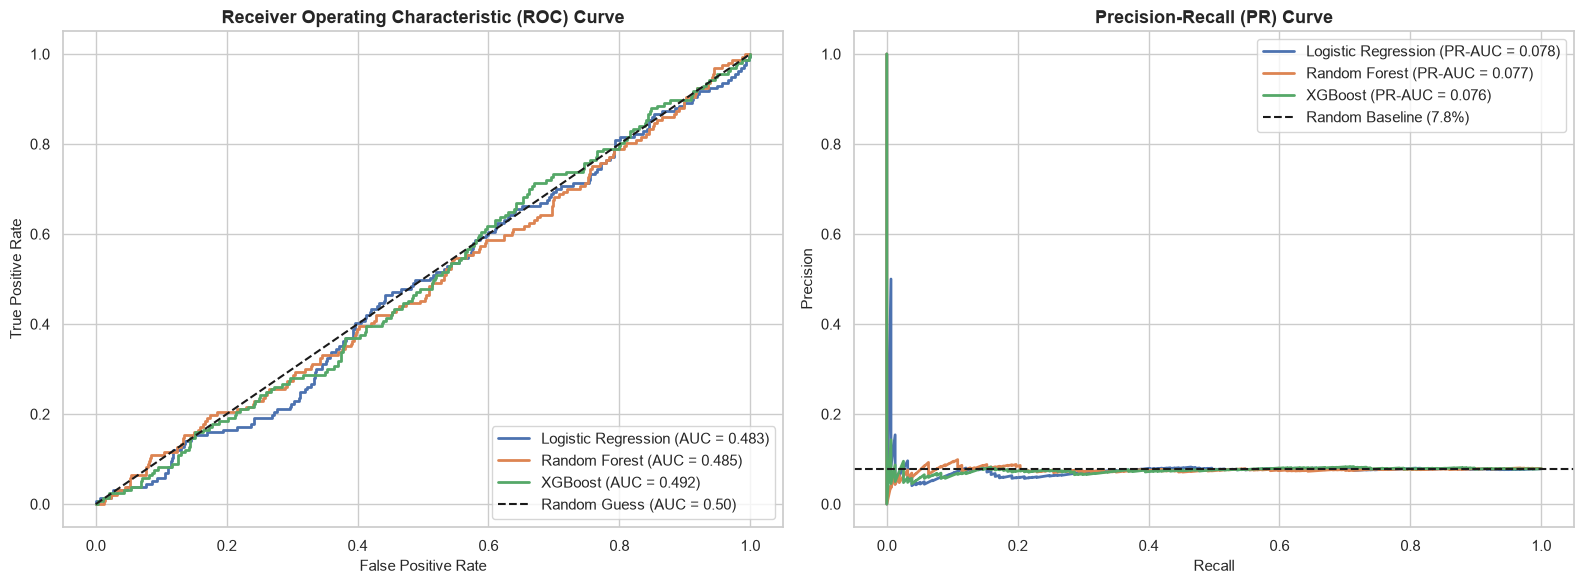

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ROC Curves
for name, data in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, data['proba'])
    auc_val = roc_auc_score(y_test, data['proba'])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", linewidth=2)

axes[0].plot([0, 1], [0, 1], 'k--', label="Random Guess (AUC = 0.50)", linewidth=1.5)
axes[0].set_title("Receiver Operating Characteristic (ROC) Curve", fontsize=13, fontweight='bold')
axes[0].set_xlabel("False Positive Rate", fontsize=11)
axes[0].set_ylabel("True Positive Rate", fontsize=11)
axes[0].legend(loc="lower right")

# Precision-Recall Curves
prevalence = float(y_test.mean())
for name, data in predictions.items():
    prec, rec, _ = precision_recall_curve(y_test, data['proba'])
    pr_auc_val = average_precision_score(y_test, data['proba'])
    axes[1].plot(rec, prec, label=f"{name} (PR-AUC = {pr_auc_val:.3f})", linewidth=2)

axes[1].axhline(y=prevalence, color='k', linestyle='--', label=f"Random Baseline ({prevalence*100:.1f}%)", linewidth=1.5)
axes[1].set_title("Precision-Recall (PR) Curve", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Recall", fontsize=11)
axes[1].set_ylabel("Precision", fontsize=11)
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()


### Calibration diagnostics

Reliability diagrams and Brier scores evaluate probability quality on the untouched holdout set. Interpret with care because the churn class is rare.

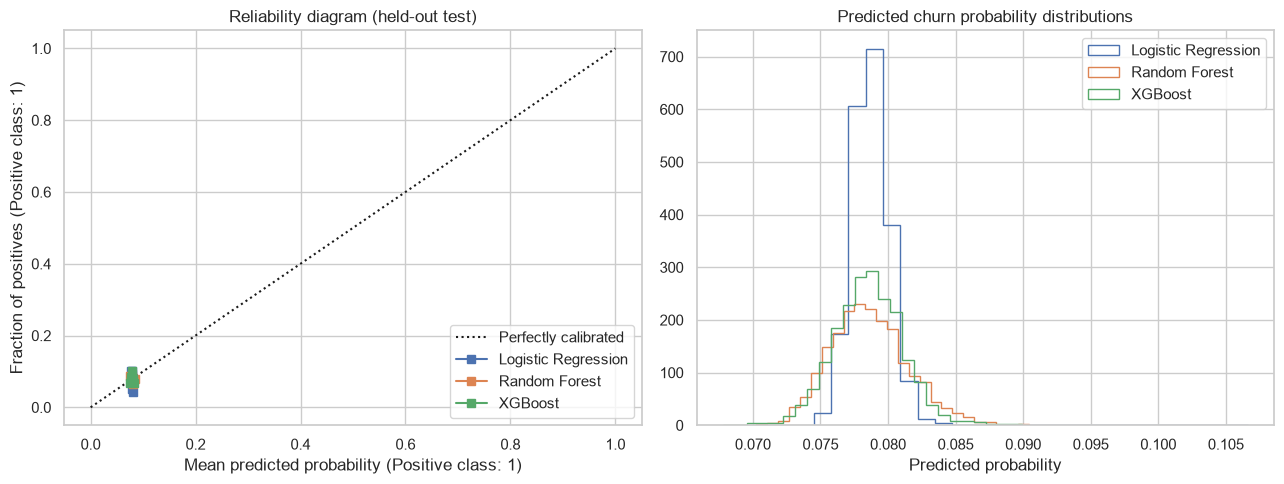

Logistic Regression Brier: 0.07236
Random Forest Brier: 0.07236
XGBoost Brier: 0.07236
Constant-prevalence Brier baseline: 0.07234


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, data in predictions.items():
    CalibrationDisplay.from_predictions(y_test, data['proba'], n_bins=8, strategy='quantile', name=name, ax=axes[0])
    axes[1].hist(data['proba'], bins=25, histtype='step', label=name)
axes[0].set_title('Reliability diagram (held-out test)')
axes[1].set_title('Predicted churn probability distributions')
axes[1].set_xlabel('Predicted probability')
axes[1].legend()
plt.tight_layout()
plt.show()
for name, data in predictions.items():
    print(name, 'Brier:', round(brier_score_loss(y_test, data['proba']), 5))
print('Constant-prevalence Brier baseline:', round(brier_score_loss(y_test, np.full(len(y_test), y_train.mean())), 5))

## 7. Feature Importance Analysis

We examine the primary feature importances from the tree ensemble (**Random Forest**) and the linear model (**Logistic Regression**) to diagnose which behavioral drivers have the highest relative weight.

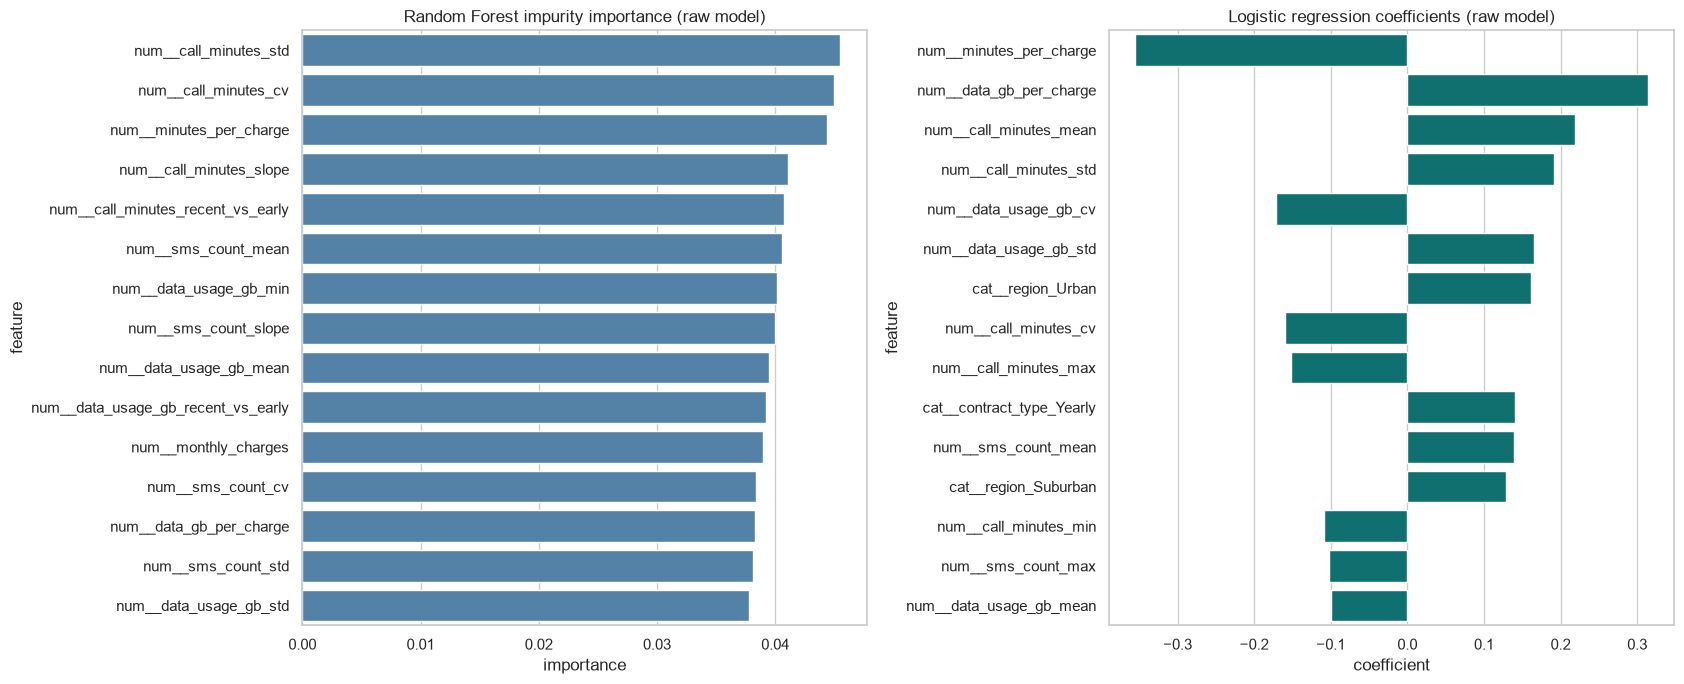

Caution: feature importance is not causal evidence; model discrimination is weak.


In [8]:
# Feature importance is extracted from a separate raw model fitted ONLY on training rows.
# This describes the uncalibrated baseline, not the ensemble of calibrated estimators.
importance_preprocessor = clone(preprocessor).fit(X_train)
X_train_proc = importance_preprocessor.transform(X_train)
feature_names = importance_preprocessor.get_feature_names_out()
lr_raw = clone(candidate_models['Logistic Regression']).fit(X_train_proc, y_train)
rf_raw = clone(candidate_models['Random Forest']).fit(X_train_proc, y_train)
rf_imp = pd.DataFrame({'feature': feature_names, 'importance': rf_raw.feature_importances_}).sort_values('importance', ascending=False)
lr_imp = pd.DataFrame({'feature': feature_names, 'coefficient': lr_raw.coef_[0]}).sort_values('coefficient', key=abs, ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
sns.barplot(data=rf_imp.head(15), x='importance', y='feature', ax=axes[0], color='steelblue')
axes[0].set_title('Random Forest impurity importance (raw model)')
sns.barplot(data=lr_imp.head(15), x='coefficient', y='feature', ax=axes[1], color='teal')
axes[1].set_title('Logistic regression coefficients (raw model)')
plt.tight_layout()
plt.show()
print('Caution: feature importance is not causal evidence; model discrimination is weak.')

## 8. Exporting a Self-Contained Calibrated Model

The saved `churn_pipeline.joblib` is itself a calibrated estimator with preprocessing inside its base pipeline; it accepts the original raw feature columns. The threshold and feature schema are saved in `churn_model_metadata.json`. Use `predict_proba` and apply the saved threshold explicitly; `predict()` defaults to 0.5.

In [9]:
# The selected object is already an end-to-end, calibrated raw-DataFrame estimator.
full_pipeline = predictions[best_model_name]['model']
model_path = MODELS_DIR / 'churn_pipeline.joblib'
joblib.dump(full_pipeline, model_path)

for name, filename in [('Logistic Regression', 'logistic_regression.joblib'),
                       ('Random Forest', 'random_forest.joblib'),
                       ('XGBoost', 'xgboost.joblib')]:
    joblib.dump(predictions[name]['model'], MODELS_DIR / filename)

# Save the training-only selected threshold and exact raw feature schema.
metadata = {
    'selected_model': best_model_name,
    'selection_metric': primary_metric,
    'threshold': float(thresholds_by_model[best_model_name]),
    'threshold_source': 'training out-of-fold predictions (nested calibration)',
    'feature_columns': X.columns.tolist(),
    'holdout_churn_prevalence': float(y_test.mean()),
    'warning': 'Experimental model: discrimination close to random; not production validated.'
}
(MODELS_DIR / 'churn_model_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
eval_df.to_csv(MODELS_DIR / 'churn_model_comparison.csv', index=False)
rf_imp.to_csv(MODELS_DIR / 'churn_feature_importance_rf.csv', index=False)
lr_imp.to_csv(MODELS_DIR / 'churn_feature_importance_lr.csv', index=False)

# Smoke test: saved artifact accepts RAW feature rows and reproduces probabilities.
loaded = joblib.load(model_path)
check_X = X_test.head(10)[metadata['feature_columns']]
original_probs = full_pipeline.predict_proba(check_X)[:, 1]
reloaded_probs = loaded.predict_proba(check_X)[:, 1]
np.testing.assert_allclose(original_probs, reloaded_probs, rtol=1e-10, atol=1e-12)
print('Saved pipeline reload check PASSED.')
print('Selected model:', best_model_name, '| decision threshold:', metadata['threshold'])
print('Saved files:')
for f in sorted(MODELS_DIR.iterdir()):
    if f.is_file() and (f.suffix in {'.joblib', '.csv', '.json'}):
        print(' -', f.name)

Saved pipeline reload check PASSED.
Selected model: Random Forest | decision threshold: 0.07122214044400618
Saved files:
 - churn_feature_importance_lr.csv
 - churn_feature_importance_rf.csv
 - churn_model_comparison.csv
 - churn_model_metadata.json
 - churn_pipeline.joblib
 - churn_preprocessor.joblib
 - cluster_preprocessor.joblib
 - kmeans_clusterer.joblib
 - logistic_regression.joblib
 - random_forest.joblib
 - xgboost.joblib


## 9. Executive Summary and Limitations

- Five-fold stratified CV and a held-out test set assess model discrimination; **Average Precision** is the primary model-selection metric because churn is rare.
- All model selection and threshold tuning occur on training data; test labels are reserved for final evaluation.
- Preprocessing is fitted inside each calibration fold, preventing fold leakage.
- Calibrated probabilities should be checked with Brier score and reliability plots; calibration does not guarantee useful discrimination.
- Weak ROC-AUC / Average Precision near baseline indicate limited evidence for reliable churn prediction. This **does not prove** that synthetic churn labels were randomly generated; that requires provenance or additional analysis.
- The saved artifact is a research prototype, **not** a production-validated retention risk engine. Do not use it to claim reliable financial impact.
- The split is stratified and random, **not temporal**. If real event dates and a prediction cutoff are available, use a temporal validation design and verify that every feature predates the outcome.